# v3 Higher-resolution CUTI: normalising CROCO $W_{MLD}$ the same way as the CUTI

Sections 1–5 are identical to `Higher_resolution_cuti.ipynb` **except the band mask: `round(mask_km/Δx)` = 12 boxes in total (coast box included), i.e. ~109 km edge to edge, instead of 13 boxes (~118 km)** (per-row CUTI on the native ~9 km grid, binned to 0.25°, 0.5°, 1°).
Sections 6–9 are new.

**The mismatch.** In `Higher_resolution_cuti.ipynb` the two sides are divided by different lengths:

* CUTI: $\;\dfrac{1}{L}\Big(Ek_t\,L + Q + \iint(\nabla\cdot u_g)\,\mathrm{MLD}\,dA\Big)$ — per metre of **coastline** $L$
* CROCO: $\;\overline{W}\times W_{band} \approx \dfrac{1}{\Delta y}\iint W\,dA$ — per metre of **latitude** $\Delta y$

with $L > \Delta y$ wherever the coast is tilted. Two ways to put both on the same footing (case 1, case 2):

| | CROCO | CUTI |
|---|---|---|
| **baseline** (as before) | $\overline{W}\times W_{band}$ | $T/L$ |
| **case 1** | $\iint W\,dA \,/\, L$ | $T/L$ (as before) |
| **case 2** | $\overline{W}\times W_{band}$ (as before) | $T/\Delta y$ |

where $T = Ek_t\,L + Q + \iint(\nabla\cdot u_g)\,\mathrm{MLD}\,dA$ is the total transport of the strip (m³/s).
In case 2 the Ekman term is also converted: $Ek_t$ is per metre of coast, so its transport is $Ek_t\,L$.

## 1. Setup

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from tqdm import tqdm

R      = 6371000.0        # Earth radius, m
Omega  = 7.2921e-5        # rotation rate, s-1
g      = 9.81             # m s-2
DEG2M  = R * np.deg2rad(1.0)

lati2, lati1  = -17, -4   # domain (south, north); bins start at lati1 and go south
lat_top_start = -4        # 1-degree bands of the original CUTI_new (check in section 6)
lat_top_end   = -17
mask_km       = 109

# None = one value per grid row (no binning)
resolutions = {'row (1/12°)': None, '0.25°': 0.25, '0.5°': 0.5, '1°': 1.0}

bs = dict(lat_band=slice(-16, -5))   # analysis range, 5S-16S (lat_band ascending here)

In [2]:
def haversine(lat1, lon1, lat2, lon2):
    lat1_rad, lon1_rad = np.deg2rad(lat1), np.deg2rad(lon1)
    lat2_rad, lon2_rad = np.deg2rad(lat2), np.deg2rad(lon2)
    a = (np.sin((lat2_rad - lat1_rad) / 2.0) ** 2
         + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin((lon2_rad - lon1_rad) / 2.0) ** 2)
    return R * 2 * np.arcsin(np.sqrt(a))


def coastal_band_mask(ds, var, target_width_km=111):
    '''Coastal band of fixed cross-shore width; coast = easternmost valid cell per row.'''
    da = ds[var]
    if 'time' in da.dims:
        da = da.isel(time=0)

    valid2d  = np.isfinite(da).values.astype(bool)
    lat_vals = ds['lat'].values
    lon_vals = ds['lon'].values
    dlon     = np.abs(lon_vals[1] - lon_vals[0])

    band = np.zeros_like(valid2d, dtype=bool)
    for j in range(valid2d.shape[0]):
        ocean_cols = np.where(valid2d[j, :])[0]
        if len(ocean_cols) == 0:
            continue
        i_coast = ocean_cols[-1]
        dx_km   = (R / 1000.0) * np.cos(np.deg2rad(lat_vals[j])) * np.deg2rad(dlon)
        n_cells = int(np.round(target_width_km / dx_km))
        # v3: n_cells boxes IN TOTAL, coast box included -> n_cells * dx ~ target_width_km edge to edge
        # (Higher_resolution_cuti keeps the coast box + n_cells more, i.e. one box (~9 km) wider)
        band[j, max(i_coast - n_cells + 1, 0):i_coast + 1] = True

    return xr.DataArray(band & valid2d, dims=('lat', 'lon'),
                        coords={'lat': ds['lat'], 'lon': ds['lon']})


def get_boundary_lons(da):
    '''Coast (easternmost) and offshore (westernmost) longitude of the band, per row.'''
    valid     = da.notnull()
    coast     = valid & (~valid.shift(lon=-1).fillna(False).astype(bool))
    offshore  = valid & (~valid.shift(lon=+1).fillna(False).astype(bool))
    return (da.lon.where(coast).min('lon'), da.lon.where(offshore).min('lon'))


def coast_row_lengths(lats, coast_lons):
    '''Along-coast length (m) attributed to each grid row: half the distance to each
    neighbouring coast cell (full distance at the two ends). Rows without coast -> NaN.'''
    lats, lon = np.asarray(lats, float), np.asarray(coast_lons, float)
    ok = np.isfinite(lon)
    la, lo = lats[ok], lon[ok]
    d  = haversine(la[:-1], lo[:-1], la[1:], lo[1:])
    ds = np.empty(len(la))
    ds[1:-1] = 0.5 * (d[:-1] + d[1:])
    ds[0], ds[-1] = d[0], d[-1]
    out = np.full(len(lats), np.nan)
    out[ok] = ds
    return xr.DataArray(out, dims='lat', coords={'lat': lats}, name='ds')


def bin_centers(lat, dbin):
    '''Centre of the half-open bin [edge - dbin, edge) each latitude falls in, edges from lati1 southward.'''
    k = np.floor((lati1 - np.asarray(lat)) / dbin + 1e-9).astype(int)
    return np.round(lati1 - (k + 0.5) * dbin, 6)


def bin_rows(da, dbin, how='sum'):
    '''Aggregate a (.., lat) row field into latitude bins of width dbin -> dim lat_band.
    dbin=None returns the rows themselves, renamed to lat_band.'''
    if dbin is None:
        return da.rename(lat='lat_band')
    da = da.assign_coords(lat_band=('lat', bin_centers(da.lat.values, dbin)))
    grp = da.groupby('lat_band')
    return grp.sum('lat', min_count=1) if how == 'sum' else grp.mean('lat')


def seasonality(data):
    return data.groupby('time.month').mean(dim='time')


def normalize(data):
    return (data - data.mean()) / data.std()

## 2. SSH, MLD, coastal band and along-coast length per row

In [3]:
# padded by 2 degrees N/S: face fluxes use shifted neighbours
reg2d = dict(lon=slice(-85, None), lat=slice(lati2 - 2, lati1 + 2))
rows  = dict(lat=slice(lati2, lati1))          # rows that enter the CUTI

# --- MLD first: it carries the land mask (SSH.nc fills land with 0.0, not NaN) ---
mld_ds = xr.open_dataset('../MLD.nc').sel(**reg2d).compute()
ocean  = np.isfinite(mld_ds.MLD.isel(time=0)).drop_vars('time')

ssh_ds = xr.open_dataset('../SSH.nc').sel(**reg2d).compute().astype('float32')
eta    = ssh_ds.SSH.where(ocean)

mask_band = coastal_band_mask(eta.isel(time=0).to_dataset(name='SSH'),
                              var='SSH', target_width_km=mask_km)
lat_all   = eta.lat.values
coast_lons, offshore_lons = get_boundary_lons(eta.isel(time=0).where(mask_band))

mld_raw = mld_ds.MLD.astype('float32')
mld     = mld_raw.where(mask_band)
del ssh_ds, mld_ds

ds_row = coast_row_lengths(lat_all, coast_lons.values)
print('grid dlat [deg]:', round(float(np.diff(lat_all).mean()), 4))
print('ds per row [km]: median %.1f, max %.1f (rows > 2x median: %d)'
      % (float(ds_row.sel(**rows).median()) / 1e3, float(ds_row.sel(**rows).max()) / 1e3,
         int((ds_row.sel(**rows) > 2 * ds_row.sel(**rows).median()).sum())))

grid dlat [deg]: 0.0816
ds per row [km]: median 11.1, max 28.2 (rows > 2x median: 4)


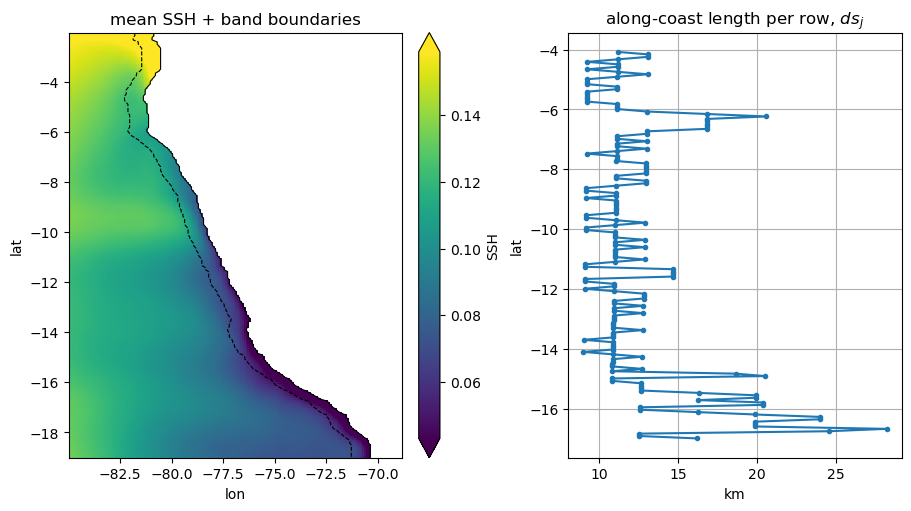

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(9, 5), constrained_layout=True)
eta.mean('time').plot(ax=ax[0], robust=True)
ax[0].plot(coast_lons, eta.lat, 'k', lw=0.8)
ax[0].plot(offshore_lons, eta.lat, 'k--', lw=0.8)
ax[0].set_title('mean SSH + band boundaries')
(ds_row.sel(**rows) / 1e3).plot(y='lat', ax=ax[1], marker='.')
ax[1].set_xlabel('km'); ax[1].set_title('along-coast length per row, $ds_j$'); ax[1].grid(True)

## 3. $UT_g$ per row (divergence form, as CUTI_new)

**v3:** the geostrophic flux through the coast face of each coast box is set to 0 (no flow through the coastline).


In [5]:
def geostrophic_from_pressure(eta, baroclinic=None):
    '''u_g, v_g (m/s) from p = rho0*g*eta, zero along the coast and over land.'''
    phi = np.deg2rad(eta.lat)
    f   = 2 * Omega * np.sin(phi)
    P   = g * eta
    if baroclinic is not None:
        P = P + baroclinic
    dP_dx = P.differentiate('lon') / (DEG2M * np.cos(phi))
    dP_dy = P.differentiate('lat') / DEG2M
    return (-dP_dy / f).fillna(0.0).rename('u_g'), (dP_dx / f).fillna(0.0).rename('v_g')


def cell_area(da):
    '''Area of each grid cell, m2.'''
    dlon = np.abs(float(da.lon[1] - da.lon[0]))
    dlat = np.abs(float(da.lat[1] - da.lat[0]))
    return (R ** 2 * np.cos(np.deg2rad(da.lat)) * np.deg2rad(dlon) * np.deg2rad(dlat))


def face_transports(u, v):
    '''Volume flux per unit depth through each cell's east / north face, m2 s-1.'''
    dlon = np.abs(float(u.lon[1] - u.lon[0]))
    dlat = np.abs(float(u.lat[1] - u.lat[0]))
    dy      = DEG2M * dlat
    lat_f   = u.lat.values + dlat / 2.0
    dx_face = xr.DataArray(DEG2M * np.cos(np.deg2rad(lat_f)) * dlon, dims='lat', coords={'lat': u.lat})
    Fe = 0.5 * (u + u.shift(lon=-1)) * dy
    Fn = 0.5 * (v + v.shift(lat=-1)) * dx_face
    return Fe.rename('Fe'), Fn.rename('Fn')


def fv_divergence(Fe, Fn, dA):
    '''Finite-volume horizontal divergence, s-1.'''
    return (((Fe - Fe.shift(lon=1)) + (Fn - Fn.shift(lat=1))) / dA).rename('div_ug')


u_g, v_g = geostrophic_from_pressure(eta)
dA       = cell_area(eta)
Fe, Fn   = face_transports(u_g, v_g)

# v3: no geostrophic flow through the coastline. The east face of the coast box would otherwise
# carry 0.5 * u_g(coast box) * dy (average with u_g = 0 on land) and act as a leak.
coast_box  = mask_band & ~mask_band.shift(lon=-1, fill_value=False)
F_leak_row = (Fe * mld.fillna(0.0)).where(coast_box).sum('lon').sel(**rows)        # m3/s removed per row
Fe         = Fe.where(~coast_box, 0.0)
div_ug   = fv_divergence(Fe, Fn, dA)

# area integral over the band cells of each row, m3/s
I_geo_row = (div_ug * mld.fillna(0.0) * dA).where(mask_band).sum('lon').sel(**rows)
print('I_geo_row:', dict(I_geo_row.sizes))
_ds = ds_row.sel(**rows)
print('removed coast-face flux / L, 5-16S mean: %+.3f m2/s' % float((F_leak_row / _ds).sel(lat=slice(-16, -5)).mean()))

I_geo_row: {'time': 432, 'lat': 159}
removed coast-face flux / L, 5-16S mean: +0.067 m2/s


### What goes into $U^{Geo}$ for one native-grid row

$$U^{Geo}_j=\frac{1}{L_j}\iint_{A_j}(\nabla\cdot u_g)\,\mathrm{MLD}\,dx\,dy \;=\; \frac{1}{L_j}\sum_{i\,\in\,A_j}(\nabla\cdot u_g)_{ij}\,\mathrm{MLD}_{ij}\,\Delta x\,\Delta y$$

* **$A_j$** (dark blue boxes) = the grid boxes of row $j$ inside the 111 km band. The $\iint dx\,dy$ is the sum over these boxes; at native resolution the $dy$ part is one box height $\Delta y$.
* **$L_j$** (red line) = the piece of coastline that belongs to row $j$: half the distance to the coast point of the row above + half to the row below. It is **not** $lat_N-lat_S$ ($=\Delta y$).

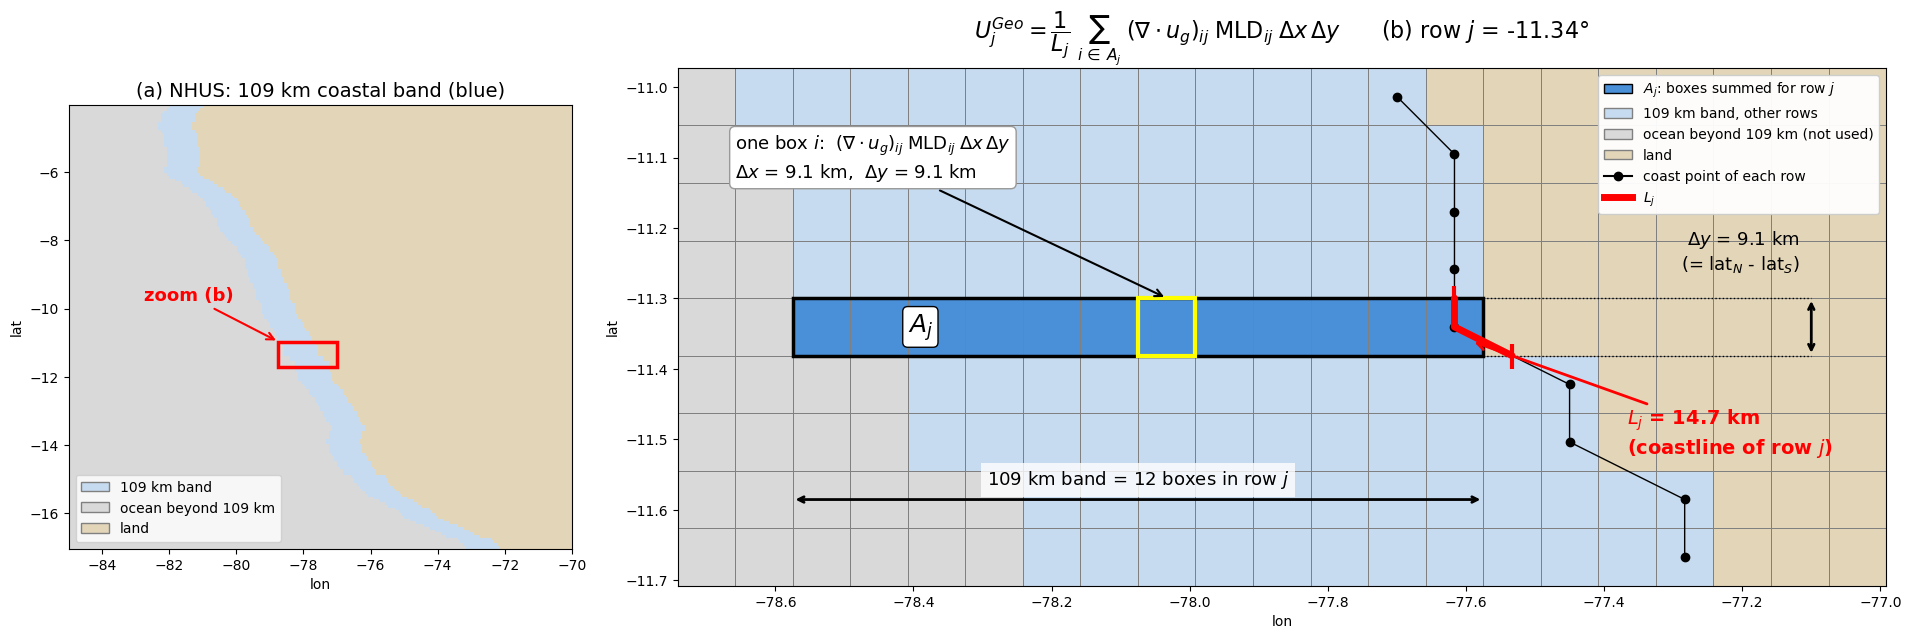

row -11.34:  12 boxes,  dy = 9.1 km,  L_j = 14.7 km,  dy/L_j = 0.62


In [6]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D

lat_r = ds_row.sel(**rows).lat.values
L_r   = ds_row.sel(**rows).values                       # m
c_lon = coast_lons.sel(**rows).values
dlon  = np.abs(float(eta.lon[1] - eta.lon[0]))

# example row: between 13S and 10S, the one where the coast steps sideways the most
cand = np.where((lat_r >= -13) & (lat_r <= -10))[0][1:-1]
k    = cand[np.nanargmax(L_r[cand])]
lat_k, lon_k = lat_r[k], c_lon[k]
jj   = int(np.argmin(np.abs(lat_all - lat_k)))
dlat = 0.5 * (lat_all[jj + 1] - lat_all[jj - 1])
dy   = DEG2M * dlat
dx   = DEG2M * np.cos(np.deg2rad(lat_k)) * dlon

strip   = mask_band.isel(lat=jj)
lon_off = float(strip.lon.where(strip, drop=True).min())   # offshore edge of the strip
n_box   = int(strip.sum())

# box categories: 0 ocean outside band, 1 band (other rows), 2 strip A_j, 3 land
cat = xr.where(~ocean, 3, xr.where(mask_band, 1, 0))
cat[dict(lat=jj)] = xr.where(strip, 2, cat.isel(lat=jj))
win = dict(lat=slice(lat_all[jj - 4] - 1e-6, lat_all[jj + 4] + 1e-6),
           lon=slice(lon_off - 2.5 * dlon, lon_k + 7.5 * dlon))
cw  = cat.sel(**win)
cmap4 = ListedColormap(['#d9d9d9', '#c6dbef', '#4a90d9', '#e3d5b8'])  # ocean beyond band, band, A_j, land

fig, (axm, ax) = plt.subplots(1, 2, figsize=(19, 8), constrained_layout=True,
                              gridspec_kw={'width_ratios': [1, 2.4]})

# (a) map of the whole NHUS band, with the zoom box
cm = cat.where(cat != 2, 1).sel(lat=slice(lati2, lati1), lon=slice(-85, -70))
axm.pcolormesh(cm.lon, cm.lat, cm, shading='nearest', vmin=-0.5, vmax=3.5, cmap=cmap4)
x0, x1 = float(cw.lon.min()) - dlon / 2, float(cw.lon.max()) + dlon / 2
y0, y1 = float(cw.lat.min()) - dlat / 2, float(cw.lat.max()) + dlat / 2
axm.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='red', lw=2.5, zorder=3))
axm.annotate('zoom (b)', xy=(x0, y1), xytext=(x0 - 4, y1 + 1.2), color='red', fontsize=13, fontweight='bold',
             arrowprops=dict(arrowstyle='->', color='red', lw=1.5))
axm.set_aspect(1 / np.cos(np.deg2rad(-10.5)))
axm.set_xlabel('lon'); axm.set_ylabel('lat')
axm.set_title(f'(a) NHUS: {mask_km} km coastal band (blue)', fontsize=14)
axm.legend(handles=[Patch(fc='#c6dbef', ec='0.5', label=f'{mask_km} km band'),
                    Patch(fc='#d9d9d9', ec='0.5', label=f'ocean beyond {mask_km} km'),
                    Patch(fc='#e3d5b8', ec='0.5', label='land')], loc='lower left', fontsize=10)
ax.pcolormesh(cw.lon, cw.lat, cw, shading='nearest', vmin=-0.5, vmax=3.5,
              cmap=cmap4,
              edgecolors='0.5', linewidth=0.5)
ax.add_patch(Rectangle((lon_off - dlon / 2, lat_k - dlat / 2), lon_k - lon_off + dlon, dlat,
                       fill=False, ec='k', lw=2.5, zorder=3))
ax.text(lon_off + 1.5 * dlon, lat_k, '$A_j$', fontsize=18, fontweight='bold', va='center', zorder=4,
        bbox=dict(fc='white', ec='k', boxstyle='round,pad=0.2'))

# coast point of each row + the piece of coast that belongs to row j
w = (lat_r >= cw.lat.min().item()) & (lat_r <= cw.lat.max().item())
ax.plot(c_lon[w], lat_r[w], 'o-', color='k', ms=6, lw=1, zorder=4)
mid_s = (0.5 * (c_lon[k - 1] + lon_k), 0.5 * (lat_r[k - 1] + lat_k))
mid_n = (0.5 * (c_lon[k + 1] + lon_k), 0.5 * (lat_r[k + 1] + lat_k))
ax.plot([mid_s[0], lon_k, mid_n[0]], [mid_s[1], lat_k, mid_n[1]], color='red', lw=5, zorder=5,
        solid_capstyle='round')
for p in (mid_s, mid_n):
    ax.plot(*p, marker='|', color='red', ms=18, mew=3, zorder=5)
ax.annotate(f'$L_j$ = {L_r[k] / 1e3:.1f} km\n(coastline of row $j$)', xy=(lon_k + 0.3 * dlon, lat_k - 0.25 * dlat),
            xytext=(lon_k + 3.0 * dlon, lat_k - 2.2 * dlat), color='red', fontsize=14, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='red', lw=2), zorder=6)

# Delta y of the row
xb = lon_k + 6.2 * dlon
ax.annotate('', xy=(xb, lat_k - dlat / 2), xytext=(xb, lat_k + dlat / 2),
            arrowprops=dict(arrowstyle='<->', color='k', lw=2))
ax.plot([lon_k + dlon / 2, xb], [lat_k + dlat / 2] * 2, 'k:', lw=1)
ax.plot([lon_k + dlon / 2, xb], [lat_k - dlat / 2] * 2, 'k:', lw=1)
ax.text(xb - 0.2 * dlon, lat_k + 1.0 * dlat, f'$\\Delta y$ = {dy / 1e3:.1f} km\n(= lat$_N$ - lat$_S$)',
        ha='right', fontsize=13)

# one box of the sum
ib = lon_off + 6 * dlon
ax.add_patch(Rectangle((ib - dlon / 2, lat_k - dlat / 2), dlon, dlat, fill=False, ec='yellow', lw=3, zorder=4))
ax.annotate('one box $i$:  $(\\nabla\\cdot u_g)_{ij}\\;\\mathrm{MLD}_{ij}\\;\\Delta x\\,\\Delta y$'
            f'\n$\\Delta x$ = {dx / 1e3:.1f} km,  $\\Delta y$ = {dy / 1e3:.1f} km',
            xy=(ib, lat_k + dlat / 2), xytext=(lon_off - 1.5 * dlon, lat_k + 2.6 * dlat), fontsize=13,
            arrowprops=dict(arrowstyle='->', color='k', lw=1.5), zorder=6,
            bbox=dict(fc='white', ec='0.6', boxstyle='round'))

# band width
yb = lat_k - 3 * dlat
ax.annotate('', xy=(lon_off - dlon / 2, yb), xytext=(lon_k + dlon / 2, yb),
            arrowprops=dict(arrowstyle='<->', color='k', lw=2))
ax.text(0.5 * (lon_off + lon_k), yb + 0.15 * dlat, f'{mask_km} km band = {n_box} boxes in row $j$',
        ha='center', va='bottom', fontsize=13, bbox=dict(fc='white', ec='none', alpha=0.8))

ax.set_title('$U^{Geo}_j = \\dfrac{1}{L_j}\\;\\sum_{i\\,\\in\\,A_j}\\;(\\nabla\\cdot u_g)_{ij}\\;'
             '\\mathrm{MLD}_{ij}\\;\\Delta x\\,\\Delta y$'
             f'      (b) row $j$ = {lat_k:.2f}°',
             fontsize=16, pad=12)
ax.set_aspect(1 / np.cos(np.deg2rad(lat_k)))
ax.set_xlim(float(cw.lon.min()) - dlon / 2, float(cw.lon.max()) + dlon / 2)
ax.set_ylim(float(cw.lat.min()) - dlat / 2, float(cw.lat.max()) + dlat / 2)
ax.set_xlabel('lon'); ax.set_ylabel('lat')
ax.legend(handles=[Patch(fc='#4a90d9', ec='k', label='$A_j$: boxes summed for row $j$'),
                   Patch(fc='#c6dbef', ec='0.5', label=f'{mask_km} km band, other rows'),
                   Patch(fc='#d9d9d9', ec='0.5', label=f'ocean beyond {mask_km} km (not used)'),
                   Patch(fc='#e3d5b8', ec='0.5', label='land'),
                   Line2D([], [], color='k', marker='o', label='coast point of each row'),
                   Line2D([], [], color='red', lw=5, label='$L_j$')],
          loc='upper right', fontsize=10, framealpha=0.95)
plt.show()

print(f'row {lat_k:.2f}:  {n_box} boxes,  dy = {dy/1e3:.1f} km,  L_j = {L_r[k]/1e3:.1f} km,  dy/L_j = {dy / L_r[k]:.2f}')

## 4. $U^{Ek}$ per row

In [7]:
# --- Ek_t: cross-shore Ekman transport at the ~111 km point of each coast point (one per row) ---
Ek_t = xr.open_dataset('Winds_components_Lu.nc').U_ek_cross.isel(offshore=0).compute()
Ek_t = (Ek_t.swap_dims({'coast_point': 'lat'})
            .drop_vars(['coast_point', 'lon', 'bearing', 'distance', 'f', 'offshore'])
            .rename('Ek_t'))
row_lats = I_geo_row.lat.values
Ek_t_row = Ek_t.reindex(lat=row_lats, method='nearest', tolerance=0.02)
print('rows without Ek_t:', int(Ek_t_row.isel(time=0).isnull().sum()), 'of', len(row_lats))

# --- meridional Ekman transport through the north face of each row's strip ---
wnd = xr.open_dataset('winds_and_components_corrected.nc')[['Uek_geo', 'Vek_geo']].sel(**reg2d)
wnd = wnd.compute().astype('float32')
mask_wind = coastal_band_mask(wnd, var='Uek_geo', target_width_km=mask_km)

V    = wnd.Vek_geo
dlon = np.abs(float(V.lon[1] - V.lon[0]))
dlat = np.abs(float(V.lat[1] - V.lat[0]))
dx_face = xr.DataArray(DEG2M * np.cos(np.deg2rad(V.lat.values + dlat / 2.0)) * dlon,
                       dims='lat', coords={'lat': V.lat})

V_face = xr.concat([V, V.shift(lat=-1)], dim='k').mean('k', skipna=True)   # at j+1/2; one-sided next to land
T_N    = (V_face * dx_face).where(mask_wind).sum('lon')                    # m3/s, north face of row j
Q_ek   = (T_N - T_N.shift(lat=1))                                          # north out - south in, m3/s
Q_ek_row = Q_ek.reindex(lat=row_lats, method='nearest', tolerance=0.02)
del wnd, V, V_face

rows without Ek_t: 0 of 159


## 5. CROCO $W_{MLD}$ per row and the CUTI at every resolution

In [8]:
wmld  = xr.open_dataset('../W_mld_Croco.nc').sel(**reg2d).compute().astype('float32')
# CUTI_new convention: band-mean W times the 111 km band width -> m2/s
W_row = (wmld.WMLD.where(mask_band).mean('lon') * mask_km * 1000).reindex(lat=row_lats, method='nearest', tolerance=0.02)
del wmld

ds_ok = ds_row.sel(**rows).where(np.isfinite(ds_row.sel(**rows)))


def cuti_at(dbin):
    '''CUTI budget aggregated to bins of width dbin (None = per row), m2/s, dim lat_band.'''
    L     = bin_rows(ds_ok, dbin)                                   # along-coast length per bin, m
    valid = ds_ok.notnull()
    UTg   = bin_rows(I_geo_row.where(valid), dbin) / L
    Q     = bin_rows(Q_ek_row.where(valid), dbin) / L
    Ekt   = bin_rows(Ek_t_row, dbin, how='mean')
    W     = bin_rows(W_row, dbin, how='mean')
    U_ek  = Ekt + Q
    out = dict(Ek_t=Ekt, Q_ek=Q, U_ek=U_ek, UTg=UTg, CUTI=U_ek + UTg, W=W, L=L)
    return {k: v.sortby('lat_band') for k, v in out.items()}


res = {name: cuti_at(d) for name, d in resolutions.items()}
for name, r in res.items():
    print(f'{name:12s} bins: {r["CUTI"].sizes["lat_band"]:4d}   '
          f'CUTI 5S-16S mean {float(r["CUTI"].sel(**bs).mean()):+6.2f}   '
          f'CROCO {float(r["W"].sel(**bs).mean()):+6.2f} m2/s')

row (1/12°)  bins:  159   CUTI 5S-16S mean  +1.81   CROCO  +1.90 m2/s
0.25°        bins:   52   CUTI 5S-16S mean  +1.82   CROCO  +1.90 m2/s
0.5°         bins:   26   CUTI 5S-16S mean  +1.82   CROCO  +1.90 m2/s
1°           bins:   13   CUTI 5S-16S mean  +1.82   CROCO  +1.90 m2/s


## 6. Transports per row in m³/s, and the two normalisations

* $\iint W\,dA$: CROCO $W_{MLD}$ summed over **the same band boxes and the same `dA`** as $UT_g$.
* $\Delta y$: the row height used inside `dA` (`cell_area` uses one constant `dlat`). With this choice, $\iint(\cdot)\,dA/\Delta y = \sum_i(\cdot)\,\Delta x$ exactly.
* Bins: m³/s are summed over the rows of a bin and divided by the summed $L$ (case 1) or the summed $\Delta y$ (case 2).

In [9]:
wmld    = xr.open_dataset('../W_mld_Croco.nc').sel(**reg2d).compute().astype('float32')
I_W_row = ((wmld.WMLD * dA).where(mask_band).sum('lon', min_count=1)
           .reindex(lat=row_lats, method='nearest', tolerance=0.02))            # m3/s
del wmld

valid  = ds_ok.notnull()
dy_c   = DEG2M * np.abs(float(eta.lat[1] - eta.lat[0]))                         # row height inside dA, m
dy_row = xr.full_like(ds_ok, dy_c).where(valid)

# total transport of each row's strip, m3/s  (CUTI before dividing by a length)
T_row = (Ek_t_row * ds_ok + Q_ek_row + I_geo_row).where(valid)

# check: how close is 'band-mean W x band width' to  iint W dA / dy ?
chk = (W_row / (I_W_row / dy_row)).sel(lat=slice(-16, -5))
print(f'dy = {dy_c / 1e3:.2f} km;  W_row / (iint W dA / dy):  median {float(chk.median()):.3f}, '
      f'5-95% {float(chk.quantile(0.05)):.3f}-{float(chk.quantile(0.95)):.3f}')
print(f'dy / L per row (5-16S): median {float((dy_row / ds_ok).sel(lat=slice(-16, -5)).median()):.2f}')


def norm_cases(name, dbin):
    '''(CUTI, CROCO) pairs for the baseline and the two consistent normalisations, m2/s, dim lat_band.'''
    base = res[name]
    L    = bin_rows(ds_ok, dbin)
    DY   = bin_rows(dy_row, dbin)
    W_L     = (bin_rows(I_W_row.where(valid), dbin) / L).sortby('lat_band')
    CUTI_dy = (bin_rows(T_row, dbin) / DY).sortby('lat_band')
    return {'baseline': (base['CUTI'], base['W']),
            'case 1: W/L': (base['CUTI'], W_L),
            'case 2: CUTI/Δy': (CUTI_dy, base['W'])}


cases = {name: norm_cases(name, d) for name, d in resolutions.items()}
for name, cs in cases.items():
    print(f'{name:12s}' + ''.join(f'   {k}: CUTI {float(C.sel(**bs).mean()):+5.2f} / CROCO {float(W.sel(**bs).mean()):+5.2f}'
                                  for k, (C, W) in cs.items()))

dy = 8.76 km;  W_row / (iint W dA / dy):  median 0.997, 5-95% 0.985-1.017
dy / L per row (5-16S): median 0.79
row (1/12°)    baseline: CUTI +1.81 / CROCO +1.90   case 1: W/L: CUTI +1.81 / CROCO +1.48   case 2: CUTI/Δy: CUTI +2.47 / CROCO +1.90
0.25°          baseline: CUTI +1.82 / CROCO +1.90   case 1: W/L: CUTI +1.82 / CROCO +1.45   case 2: CUTI/Δy: CUTI +2.47 / CROCO +1.90
0.5°           baseline: CUTI +1.82 / CROCO +1.90   case 1: W/L: CUTI +1.82 / CROCO +1.44   case 2: CUTI/Δy: CUTI +2.47 / CROCO +1.90
1°             baseline: CUTI +1.82 / CROCO +1.90   case 1: W/L: CUTI +1.82 / CROCO +1.42   case 2: CUTI/Δy: CUTI +2.47 / CROCO +1.90


## 7. Skill: baseline vs case 1 vs case 2

Same metrics as section 9 of `Higher_resolution_cuti.ipynb`.
Note: within one row, each case only multiplies CUTI and CROCO by constants in time, so **r(time) per row is the same in all three**; the differences show up in the time-mean profile (r, RMSE, bias) and in the 5–16°S mean.

In [10]:
import pandas as pd

def skill_row(C, W):
    C, W = C.sel(**bs), W.sel(**bs)
    Cp, Wp = C.mean('time'), W.mean('time')
    cs, ws = C.mean('lat_band'), W.mean('lat_band')
    return {'r(time) mean': float(xr.corr(C, W, dim='time').mean()),
            'r(profile)': float(xr.corr(Cp, Wp)),
            'RMSE prof': float(np.sqrt(((Cp - Wp) ** 2).mean())),
            'bias': float((C - W).mean()),
            'CUTI/CROCO (mean)': float(C.mean() / W.mean()),
            'r(5-16S)': float(xr.corr(cs, ws)),
            'r seas.': float(xr.corr(seasonality(cs), seasonality(ws)))}

tab = pd.DataFrame({(name, k): skill_row(C, W) for name, cs in cases.items() for k, (C, W) in cs.items()}).T
tab.index.names = ['resolution', 'normalisation']
tab.round(3)

r(time) mean  r(profile)  RMSE prof   bias  \
resolution  normalisation                                                 
row (1/12°) baseline                0.381       0.484      0.895 -0.083   
            case 1: W/L             0.381       0.486      0.862  0.333   
            case 2: CUTI/Δy         0.381       0.259      1.320  0.569   
0.25°       baseline                0.454       0.623      0.588 -0.079   
            case 1: W/L             0.454       0.609      0.653  0.369   
            case 2: CUTI/Δy         0.454       0.346      1.047  0.578   
0.5°        baseline                0.576       0.690      0.508 -0.077   
            case 1: W/L             0.576       0.708      0.573  0.384   
            case 2: CUTI/Δy         0.575       0.421      0.926  0.571   
1°          baseline                0.739       0.619      0.431 -0.072   
            case 1: W/L             0.739       0.665      0.526  0.406   
            case 2: CUTI/Δy         0.738       0.386      0.791  0.574   

                             CUTI/CROCO (mean)  r(5-16S)  r seas.  
resolution  normalisation                                          
row (1/12°) baseline                     0.956     0.929    0.996  
            case 1: W/L                  1.225     0.931    0.996  
            case 2: CUTI/Δy              1.300     0.932    0.996  
0.25°       baseline                     0.958     0.927    0.996  
            case 1: W/L                  1.255     0.929    0.996  
            case 2: CUTI/Δy              1.305     0.932    0.996  
0.5°        baseline                     0.959     0.929    0.996  
            case 1: W/L                  1.267     0.930    0.996  
            case 2: CUTI/Δy              1.301     0.931    0.996  
1°          baseline                     0.962     0.930    0.996  
            case 1: W/L                  1.287     0.931    0.996  
            case 2: CUTI/Δy              1.303     0.932    0.996

## 8. Time-mean profiles

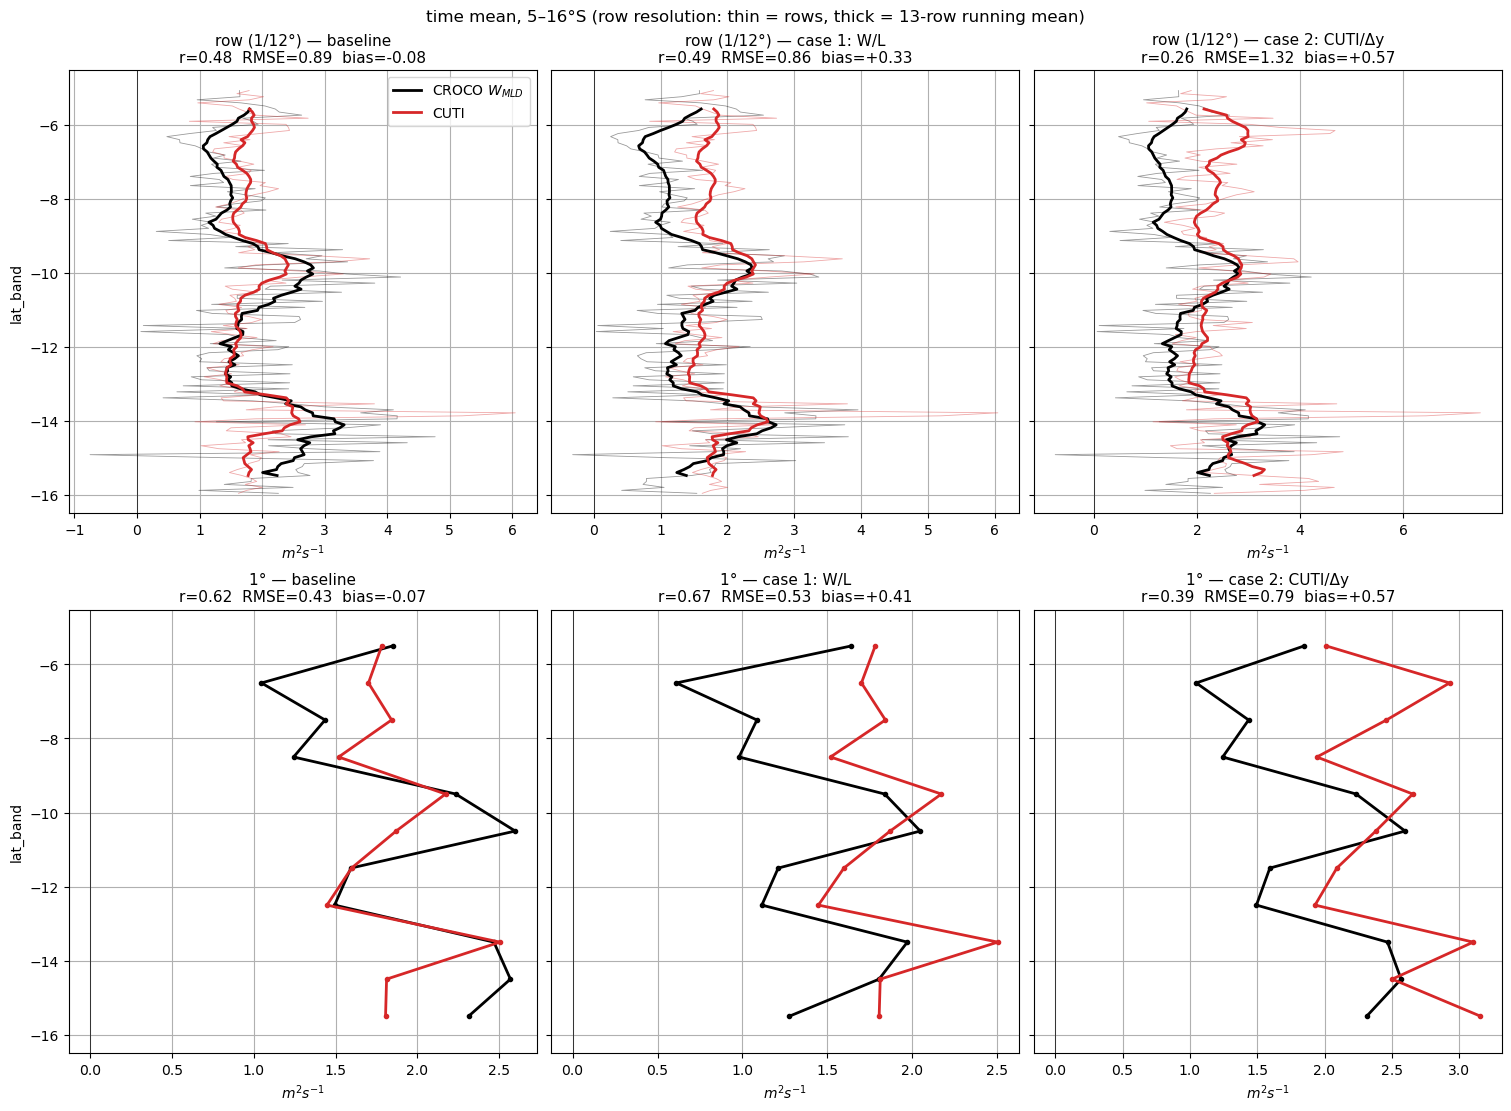

In [11]:
cname = list(cases['row (1/12°)'])
fig, ax = plt.subplots(2, len(cname), figsize=(5 * len(cname), 11), sharey=True, constrained_layout=True)
for i, name in enumerate(['row (1/12°)', '1°']):
    for j, k in enumerate(cname):
        a = ax[i, j]
        C, W = (v.sel(**bs).mean('time') for v in cases[name][k])
        if name.startswith('row'):
            W.plot(y='lat_band', ax=a, color='k', lw=0.6, alpha=0.4)
            C.plot(y='lat_band', ax=a, color='tab:red', lw=0.6, alpha=0.4)
            W = W.rolling(lat_band=13, center=True).mean()
            C = C.rolling(lat_band=13, center=True).mean()
        W.plot(y='lat_band', ax=a, color='k', lw=2, label='CROCO $W_{MLD}$', marker='.' if name == '1°' else None)
        C.plot(y='lat_band', ax=a, color='tab:red', lw=2, label='CUTI', marker='.' if name == '1°' else None)
        s = tab.loc[(name, k)]
        a.set_title(f'{name} — {k}\nr={s["r(profile)"]:.2f}  RMSE={s["RMSE prof"]:.2f}  bias={s["bias"]:+.2f}',
                    fontsize=11)
        a.axvline(0, color='k', lw=0.5); a.set_xlabel('$m^2 s^{-1}$'); a.grid(True)
        if j: a.set_ylabel('')
ax[0, 0].legend()
fig.suptitle('time mean, 5–16°S (row resolution: thin = rows, thick = 13-row running mean)')
plt.show()

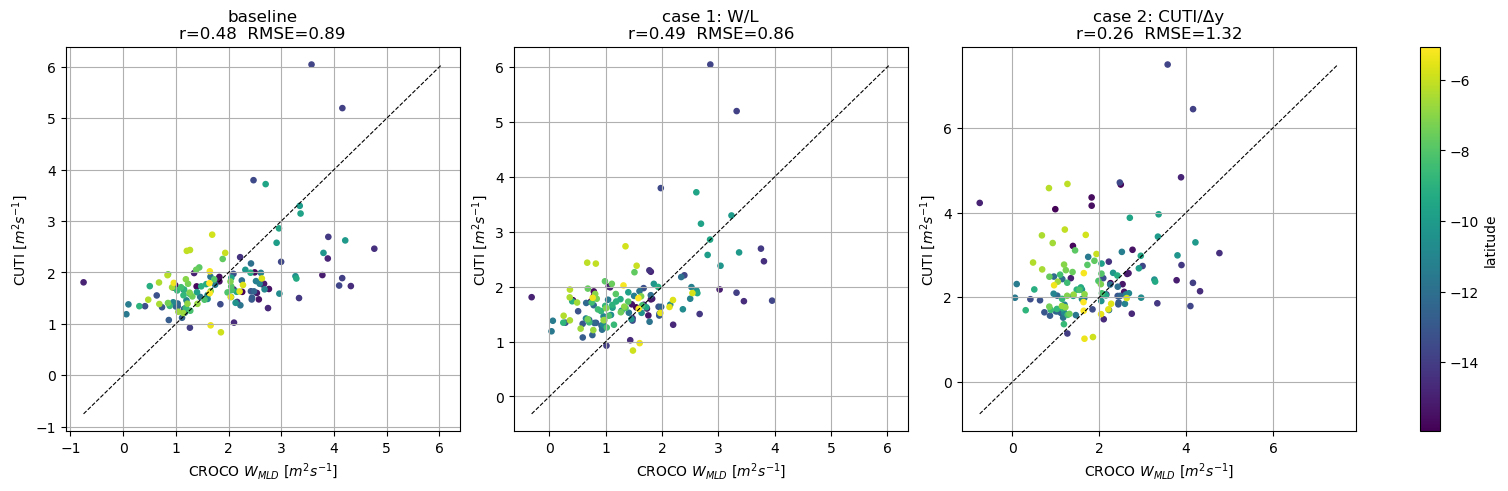

In [12]:
# time-mean CUTI vs CROCO, one point per row
fig, ax = plt.subplots(1, len(cname), figsize=(5 * len(cname), 4.8), constrained_layout=True)
for a, k in zip(ax, cname):
    C, W = (v.sel(**bs).mean('time') for v in cases['row (1/12°)'][k])
    sc = a.scatter(W, C, c=C.lat_band, cmap='viridis', s=14)
    lim = [float(min(W.min(), C.min())), float(max(W.max(), C.max()))]
    a.plot(lim, lim, 'k--', lw=0.8)
    s = tab.loc[('row (1/12°)', k)]
    a.set_title(f'{k}\nr={s["r(profile)"]:.2f}  RMSE={s["RMSE prof"]:.2f}')
    a.set_xlabel('CROCO $W_{MLD}$ [$m^2 s^{-1}$]'); a.set_ylabel('CUTI [$m^2 s^{-1}$]'); a.grid(True)
plt.colorbar(sc, ax=ax, label='latitude')
plt.show()

## 10. $U^{Ek}$ in divergence form (same as $U^{Geo}$), and the normalisations again

$$U^{Ek}_j = \frac{1}{L_j}\iint_{A_j}\nabla\cdot\mathbf{U}_{ek}\,dA$$

The code is the same as in `v2.Higher_resolution_cuti.ipynb`: same grid, face fluxes, band boxes and `dA` as $U^{Geo}$; land → 0, and the Ekman flux through the coast face of each coast box → 0 (as for $U^{Geo}$), so nothing flows through the coastline. There is no MLD factor, because Ekman transport is already depth-integrated.

With this, CUTI and CROCO are both **area integrals over exactly the same boxes**:
$T^{div} = \iint\nabla\cdot\mathbf U_{ek}\,dA + \iint(\nabla\cdot u_g)\,\mathrm{MLD}\,dA$ vs $\iint W\,dA$.
Dividing both by $L$ (case 1) gives CUTI and CROCO in the same units, over the same boxes.

In [13]:
wnd = xr.open_dataset('winds_and_components_corrected.nc')[['Uek_geo', 'Vek_geo']].sel(**reg2d)
wnd = wnd.compute().astype('float32')
assert np.allclose(wnd.lat, eta.lat) and np.allclose(wnd.lon, eta.lon), 'wind and SSH grids differ'

coast_cell = mask_band & ~mask_band.shift(lon=-1, fill_value=False)
U_ek2d = wnd.Uek_geo.where(ocean).fillna(0.0)
V_ek2d = wnd.Vek_geo.where(ocean).fillna(0.0)
Fe_ek, Fn_ek = face_transports(U_ek2d, V_ek2d)
# no Ekman flow through the coastline: same treatment as the geostrophic flux in section 3
F_leak_ek = Fe_ek.where(coast_cell).sum('lon').sel(**rows)
Fe_ek = Fe_ek.where(~coast_cell, 0.0)
print('removed Ekman coast-face flux / L, 5-16S mean: %+.3f m2/s'
      % float((F_leak_ek / ds_row.sel(**rows)).sel(lat=slice(-16, -5)).mean()))
div_ek = fv_divergence(Fe_ek, Fn_ek, dA)
I_ek_row = (div_ek * dA).where(mask_band).sum('lon').sel(**rows)              # m3/s
del wnd, U_ek2d, V_ek2d, Fe_ek, Fn_ek

T_div_row = (I_ek_row + I_geo_row).where(valid)                               # total, m3/s


def div_cases(name, dbin):
    L, DY = bin_rows(ds_ok, dbin), bin_rows(dy_row, dbin)
    s     = lambda x: x.sortby('lat_band')
    T     = bin_rows(T_div_row, dbin)
    IW    = bin_rows(I_W_row.where(valid), dbin)
    Uek_L = s(bin_rows(I_ek_row.where(valid), dbin) / L)
    return {'baseline':               (s(T / L),  res[name]['W']),
            'case 1: W/L':            (s(T / L),  s(IW / L)),
            'case 2: CUTI/Δy':        (s(T / DY), res[name]['W']),
            '_Uek_L': Uek_L}


cases_div = {name: div_cases(name, d) for name, d in resolutions.items()}
r0d = cases_div['row (1/12°)']
print('5-16S time mean, rows [m2/s]:  U_ek (div) = %+.2f   U_ek (Ek_t + Q) = %+.2f   U_geo = %+.2f'
      % (float(r0d['_Uek_L'].sel(**bs).mean()), float(res['row (1/12°)']['U_ek'].sel(**bs).mean()),
         float(res['row (1/12°)']['UTg'].sel(**bs).mean())))

removed Ekman coast-face flux / L, 5-16S mean: -0.827 m2/s


5-16S time mean, rows [m2/s]:  U_ek (div) = +1.88   U_ek (Ek_t + Q) = +2.14   U_geo = -0.33


In [14]:
rows_tab = {}
for name in resolutions:
    for k in cname:
        rows_tab[(name, 'Ek_t + Q (as now)', k)] = skill_row(*cases[name][k])
        rows_tab[(name, 'divergence', k)]       = skill_row(*cases_div[name][k])
tab2 = pd.DataFrame(rows_tab).T
tab2.index.names = ['resolution', 'U^Ek', 'normalisation']
tab2.round(3)

r(time) mean  r(profile)  \
resolution  U^Ek              normalisation                               
row (1/12°) Ek_t + Q (as now) baseline                0.381       0.484   
            divergence        baseline                0.351       0.438   
            Ek_t + Q (as now) case 1: W/L             0.381       0.486   
            divergence        case 1: W/L             0.351       0.503   
            Ek_t + Q (as now) case 2: CUTI/Δy         0.381       0.259   
            divergence        case 2: CUTI/Δy         0.351       0.271   
0.25°       Ek_t + Q (as now) baseline                0.454       0.623   
            divergence        baseline                0.419       0.641   
            Ek_t + Q (as now) case 1: W/L             0.454       0.609   
            divergence        case 1: W/L             0.419       0.676   
            Ek_t + Q (as now) case 2: CUTI/Δy         0.454       0.346   
            divergence        case 2: CUTI/Δy         0.419       0.476   
0.5°        Ek_t + Q (as now) baseline                0.576       0.690   
            divergence        baseline                0.539       0.676   
            Ek_t + Q (as now) case 1: W/L             0.576       0.708   
            divergence        case 1: W/L             0.539       0.745   
            Ek_t + Q (as now) case 2: CUTI/Δy         0.575       0.421   
            divergence        case 2: CUTI/Δy         0.539       0.549   
1°          Ek_t + Q (as now) baseline                0.739       0.619   
            divergence        baseline                0.704       0.553   
            Ek_t + Q (as now) case 1: W/L             0.739       0.665   
            divergence        case 1: W/L             0.704       0.705   
            Ek_t + Q (as now) case 2: CUTI/Δy         0.738       0.386   
            divergence        case 2: CUTI/Δy         0.704       0.515   

                                               RMSE prof   bias  \
resolution  U^Ek              normalisation                       
row (1/12°) Ek_t + Q (as now) baseline             0.895 -0.083   
            divergence        baseline             0.993 -0.341   
            Ek_t + Q (as now) case 1: W/L          0.862  0.333   
            divergence        case 1: W/L          0.795  0.075   
            Ek_t + Q (as now) case 2: CUTI/Δy      1.320  0.569   
            divergence        case 2: CUTI/Δy      1.139  0.182   
0.25°       Ek_t + Q (as now) baseline             0.588 -0.079   
            divergence        baseline             0.671 -0.348   
            Ek_t + Q (as now) case 1: W/L          0.653  0.369   
            divergence        case 1: W/L          0.509  0.100   
            Ek_t + Q (as now) case 2: CUTI/Δy      1.047  0.578   
            divergence        case 2: CUTI/Δy      0.760  0.190   
0.5°        Ek_t + Q (as now) baseline             0.508 -0.077   
            divergence        baseline             0.621 -0.352   
            Ek_t + Q (as now) case 1: W/L          0.573  0.384   
            divergence        case 1: W/L          0.418  0.110   
            Ek_t + Q (as now) case 2: CUTI/Δy      0.926  0.571   
            divergence        case 2: CUTI/Δy      0.645  0.184   
1°          Ek_t + Q (as now) baseline             0.431 -0.072   
            divergence        baseline             0.571 -0.353   
            Ek_t + Q (as now) case 1: W/L          0.526  0.406   
            divergence        case 1: W/L          0.341  0.125   
            Ek_t + Q (as now) case 2: CUTI/Δy      0.791  0.574   
            divergence        case 2: CUTI/Δy      0.506  0.187   

                                               CUTI/CROCO (mean)  r(5-16S)  \
resolution  U^Ek              normalisation                                  
row (1/12°) Ek_t + Q (as now) baseline                     0.956     0.929   
            divergence        baseline                     0.820     0.907   
            Ek_t + Q (as now) case 1: W/L

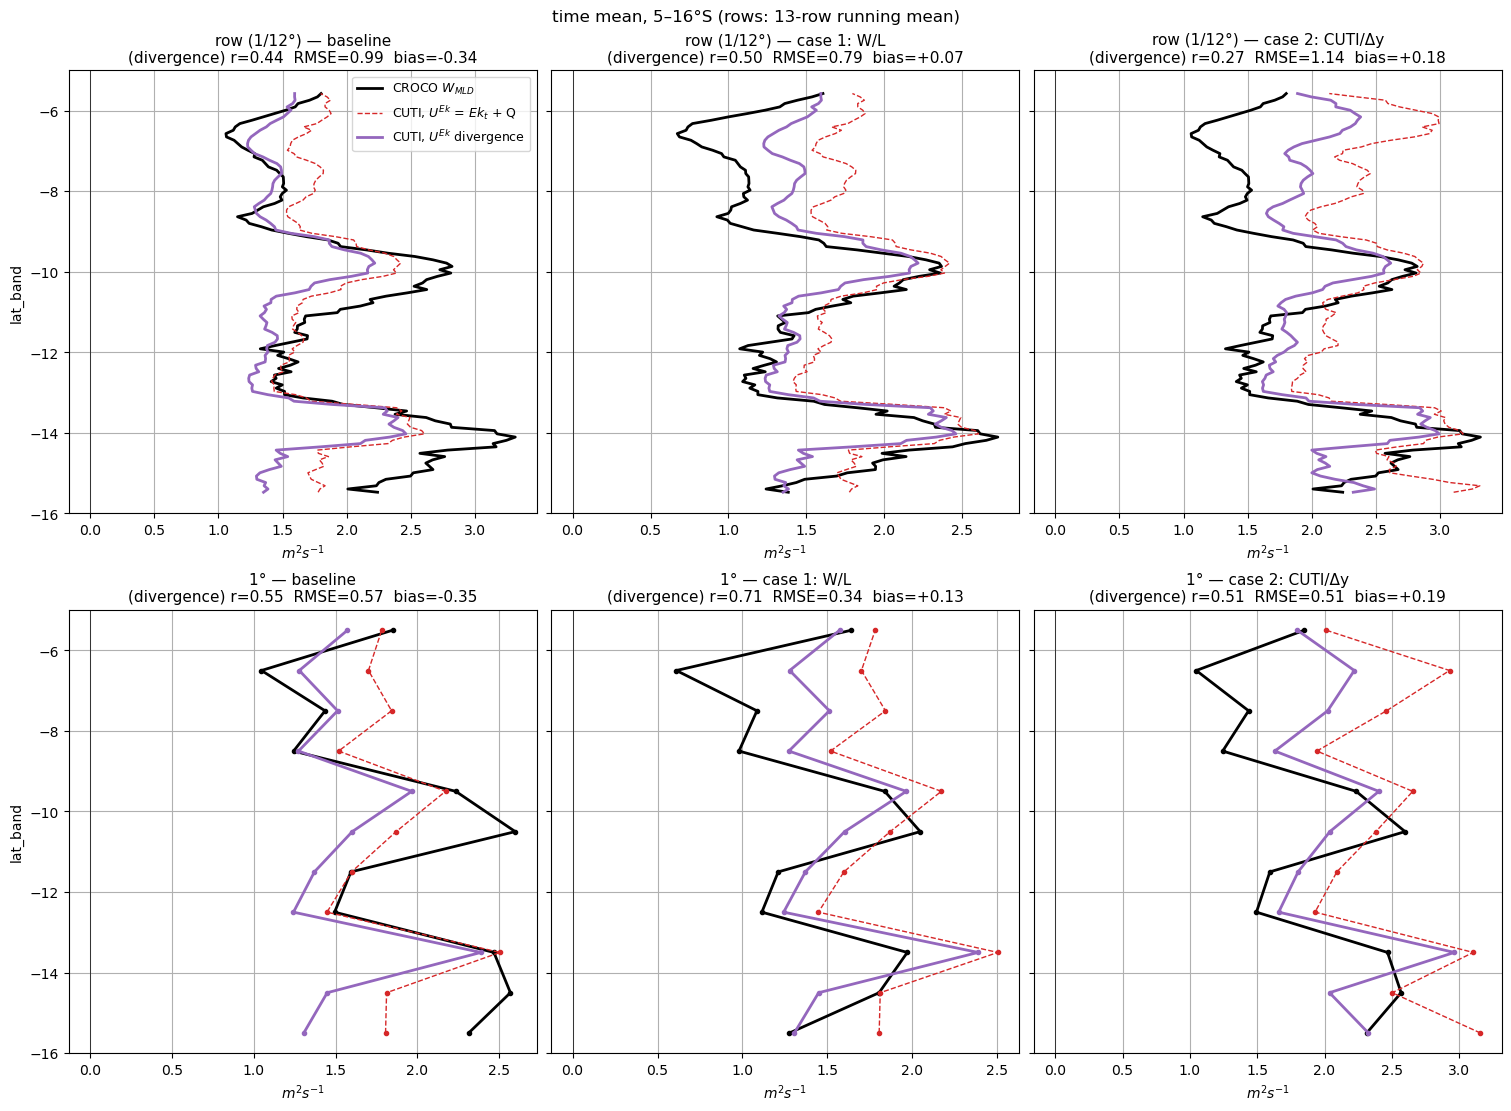

In [15]:
fig, ax = plt.subplots(2, len(cname), figsize=(5 * len(cname), 11), sharey=True, constrained_layout=True)
for i, name in enumerate(['row (1/12°)', '1°']):
    for j, k in enumerate(cname):
        a = ax[i, j]
        Cv1 = cases[name][k][0].sel(**bs).mean('time')
        C, W = (v.sel(**bs).mean('time') for v in cases_div[name][k])
        if name.startswith('row'):
            sm = lambda x: x.rolling(lat_band=13, center=True).mean()
            W, C, Cv1 = sm(W), sm(C), sm(Cv1)
        mk = '.' if name == '1°' else None
        W.plot(y='lat_band', ax=a, color='k', lw=2, label='CROCO $W_{MLD}$', marker=mk)
        Cv1.plot(y='lat_band', ax=a, color='tab:red', lw=1, ls='--', label='CUTI, $U^{Ek}$ = $Ek_t$ + Q', marker=mk)
        C.plot(y='lat_band', ax=a, color='tab:purple', lw=2, label='CUTI, $U^{Ek}$ divergence', marker=mk)
        s = tab2.loc[(name, 'divergence', k)]
        a.set_title(f'{name} — {k}\n(divergence) r={s["r(profile)"]:.2f}  RMSE={s["RMSE prof"]:.2f}  '
                    f'bias={s["bias"]:+.2f}', fontsize=11)
        a.axvline(0, color='k', lw=0.5); a.set_xlabel('$m^2 s^{-1}$'); a.grid(True)
        if j: a.set_ylabel('')
ax[0, 0].legend(fontsize=9)
fig.suptitle('time mean, 5–16°S (rows: 13-row running mean)')
plt.show()

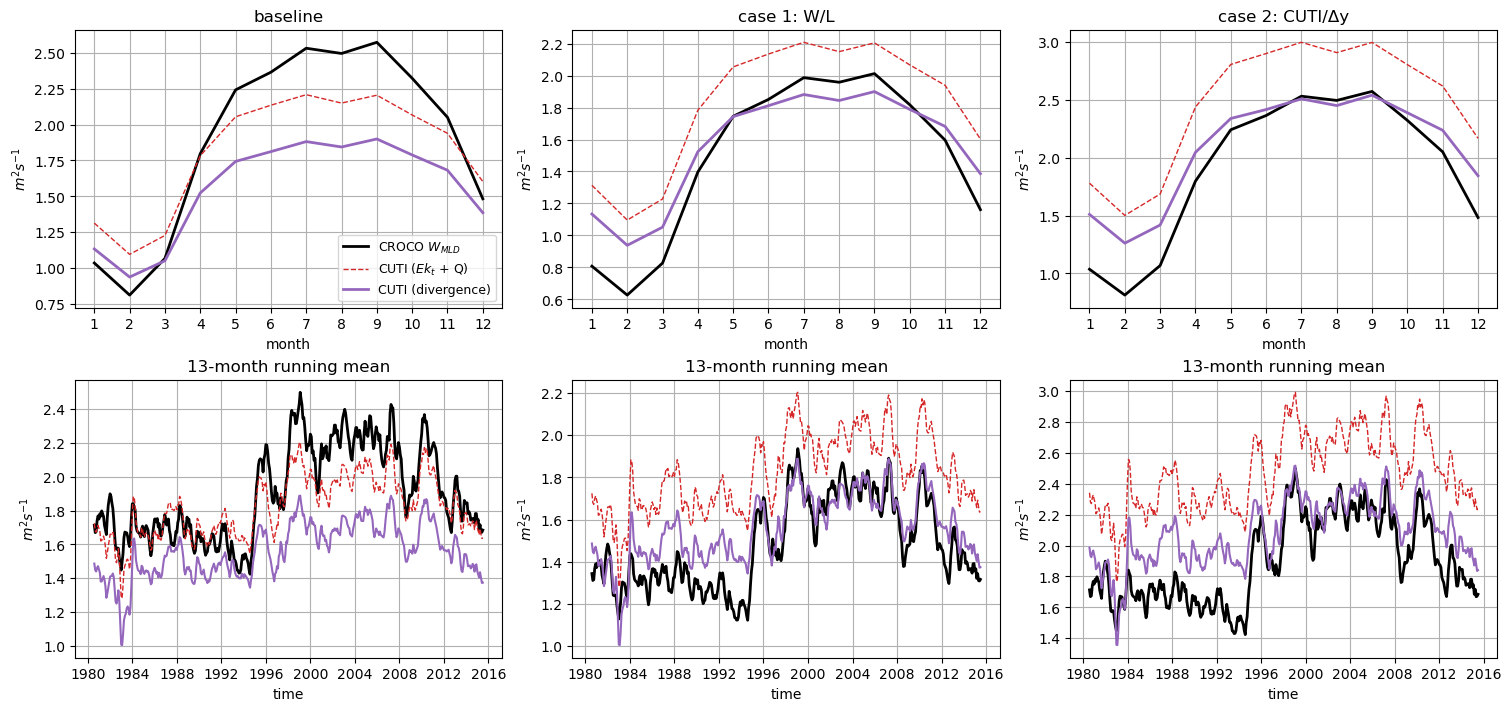

In [16]:
fig, ax = plt.subplots(2, len(cname), figsize=(5 * len(cname), 7), constrained_layout=True)
for j, k in enumerate(cname):
    C, W = (v.sel(**bs).mean('lat_band') for v in cases_div['row (1/12°)'][k])
    Cv1 = cases['row (1/12°)'][k][0].sel(**bs).mean('lat_band')
    seasonality(W).plot(ax=ax[0, j], color='k', lw=2, label='CROCO $W_{MLD}$')
    seasonality(Cv1).plot(ax=ax[0, j], color='tab:red', lw=1, ls='--', label='CUTI ($Ek_t$ + Q)')
    seasonality(C).plot(ax=ax[0, j], color='tab:purple', lw=2, label='CUTI (divergence)')
    ax[0, j].set_title(k); ax[0, j].set_xticks(range(1, 13)); ax[0, j].grid(True)
    W.rolling(time=13, center=True).mean().plot(ax=ax[1, j], color='k', lw=2)
    Cv1.rolling(time=13, center=True).mean().plot(ax=ax[1, j], color='tab:red', lw=1, ls='--')
    C.rolling(time=13, center=True).mean().plot(ax=ax[1, j], color='tab:purple', lw=1.5)
    ax[1, j].set_title('13-month running mean'); ax[1, j].grid(True)
    for a in ax[:, j]:
        a.set_ylabel('$m^2 s^{-1}$')
ax[0, 0].legend(fontsize=9)
plt.show()

## 11. Map: band width and what $\Delta y / L$ does

* **(b) one row.** The v3 mask keeps `round(mask_km / Δx)` = 12 boxes **including** the coast box, so the boxes that are summed span 12 Δx ≈ 109 km edge to edge, the same width `mask_km` used for the old CROCO normalisation.
* **(c) a 1.5° stretch of coast.** That width is measured **east–west**. The coast is tilted, so the band's thickness **perpendicular to the coast** is width × cos θ.
  Dividing by $L$ instead of $\Delta y$ does this conversion. $L$ follows the **grid** coastline, including its steps, so it is a bit longer than a straight coast and $\Delta y/L$ is a bit smaller than $\cos\theta$ (both printed in panel c).
  So case 1 is "upwelling per metre of (grid) coastline": tilt + steps of the coast are both accounted for, the same way as for $U^{Geo}$ and $U^{Ek}$.

boxes per row: [np.int64(12)];  centre-to-centre 98-102 km;  edge-to-edge 107-111 km


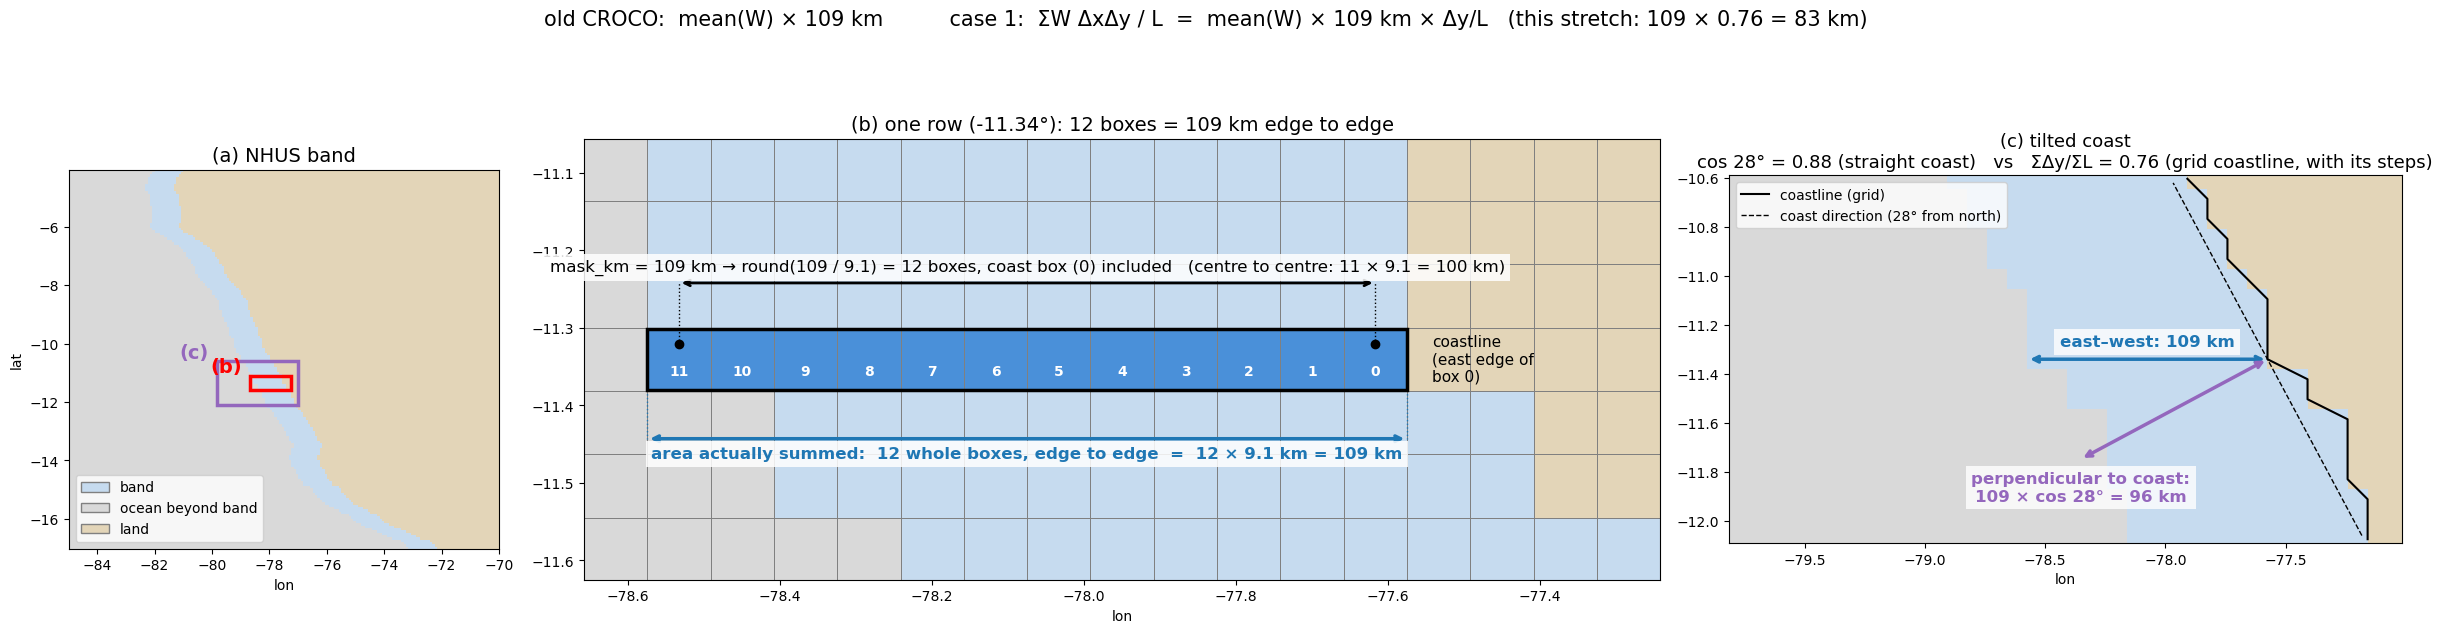

In [17]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle, Patch

cmap4 = ListedColormap(['#d9d9d9', '#c6dbef', '#4a90d9', '#e3d5b8'])   # ocean beyond band, band, row j, land
lat_r = ds_row.sel(**rows).lat.values
L_r   = ds_row.sel(**rows).values
c_lon = coast_lons.sel(**rows).values
dlon_g = np.abs(float(eta.lon[1] - eta.lon[0]))
dlat_g = np.abs(float(eta.lat[1] - eta.lat[0]))

# boxes per row and edge-to-edge width, all rows 5-16S
nbox = mask_band.sum('lon').sel(lat=slice(-16, -5))
dxr  = DEG2M * np.cos(np.deg2rad(nbox.lat)) * dlon_g
print(f'boxes per row: {sorted(set(nbox.values.astype(int)))};  '
      f'centre-to-centre {float(((nbox - 1) * dxr).min()) / 1e3:.0f}-{float(((nbox - 1) * dxr).max()) / 1e3:.0f} km;  '
      f'edge-to-edge {float((nbox * dxr).min()) / 1e3:.0f}-{float((nbox * dxr).max()) / 1e3:.0f} km')

# example row (as in section 3)
cand = np.where((lat_r >= -13) & (lat_r <= -10))[0][1:-1]
k    = cand[np.nanargmax(L_r[cand])]
lat_k, lon_k = lat_r[k], c_lon[k]
jj   = int(np.argmin(np.abs(lat_all - lat_k)))
dx_k = DEG2M * np.cos(np.deg2rad(lat_k)) * dlon_g
strip   = mask_band.isel(lat=jj)
n_k     = int(strip.sum())
lon_off = lon_k - (n_k - 1) * dlon_g
cat = xr.where(~ocean, 3, xr.where(mask_band, 1, 0))
cat[dict(lat=jj)] = xr.where(strip, 2, cat.isel(lat=jj))

fig, ax = plt.subplots(1, 3, figsize=(24, 6.8), constrained_layout=True, gridspec_kw={'width_ratios': [0.8, 2.0, 1.25]})

# ---------- (a) map ----------
cm = cat.where(cat != 2, 1).sel(lat=slice(lati2, lati1), lon=slice(-85, -70))
ax[0].pcolormesh(cm.lon, cm.lat, cm, shading='nearest', vmin=-0.5, vmax=3.5, cmap=cmap4)
win_b = dict(lat=slice(lat_all[jj - 3] - 1e-6, lat_all[jj + 3] + 1e-6), lon=slice(lon_off - 1.5 * dlon_g, lon_k + 4.5 * dlon_g))
win_c = dict(lat=slice(lat_k - 0.75, lat_k + 0.75), lon=slice(lon_k - 2.2, lon_k + 0.6))
for w, c, t in [(win_c, 'tab:purple', '(c)'), (win_b, 'red', '(b)')]:
    x0, x1, y0, y1 = w['lon'].start, w['lon'].stop, w['lat'].start, w['lat'].stop
    ax[0].add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=c, lw=2.5, zorder=3))
    ax[0].text(x0 - 0.3, y1 + 0.1, t, color=c, fontsize=14, fontweight='bold', ha='right')
ax[0].set_aspect(1 / np.cos(np.deg2rad(-10.5)))
ax[0].set_title('(a) NHUS band', fontsize=14); ax[0].set_xlabel('lon'); ax[0].set_ylabel('lat')
ax[0].legend(handles=[Patch(fc='#c6dbef', ec='0.5', label='band'), Patch(fc='#d9d9d9', ec='0.5', label='ocean beyond band'),
                      Patch(fc='#e3d5b8', ec='0.5', label='land')], loc='lower left', fontsize=10)

# ---------- (b) one row: 109 km centre-to-centre vs 118 km edge-to-edge ----------
a = ax[1]
cw = cat.sel(**win_b)
a.pcolormesh(cw.lon, cw.lat, cw, shading='nearest', vmin=-0.5, vmax=3.5, cmap=cmap4, edgecolors='0.5', linewidth=0.5)
a.add_patch(Rectangle((lon_off - dlon_g / 2, lat_k - dlat_g / 2), n_k * dlon_g, dlat_g, fill=False, ec='k', lw=2.5, zorder=3))
for i in range(n_k):                                                         # box numbers
    a.text(lon_k - i * dlon_g, lat_k - 0.2 * dlat_g, str(i), ha='center', va='center', fontsize=10, color='white', fontweight='bold', zorder=4)
a.plot([lon_off, lon_k], [lat_k + 0.25 * dlat_g] * 2, 'o', color='k', ms=6, zorder=5)
y1 = lat_k + 1.25 * dlat_g
a.annotate('', xy=(lon_off, y1), xytext=(lon_k, y1), arrowprops=dict(arrowstyle='<->', color='k', lw=2))
a.plot([lon_off, lon_off], [lat_k + 0.25 * dlat_g, y1], 'k:', lw=1); a.plot([lon_k, lon_k], [lat_k + 0.25 * dlat_g, y1], 'k:', lw=1)
a.text(0.5 * (lon_off + lon_k), y1 + 0.12 * dlat_g,
       f'mask_km = {mask_km} km → round({mask_km} / {dx_k / 1e3:.1f}) = {n_k} boxes, coast box (0) included'
       f'   (centre to centre: {n_k - 1} × {dx_k / 1e3:.1f} = {(n_k - 1) * dx_k / 1e3:.0f} km)',
       ha='center', va='bottom', fontsize=12, bbox=dict(fc='white', ec='none', alpha=0.85))
y2 = lat_k - 1.3 * dlat_g
xe0, xe1 = lon_off - dlon_g / 2, lon_k + dlon_g / 2
a.annotate('', xy=(xe0, y2), xytext=(xe1, y2), arrowprops=dict(arrowstyle='<->', color='tab:blue', lw=2.5))
a.plot([xe0, xe0], [lat_k - dlat_g / 2, y2], color='tab:blue', ls=':', lw=1)
a.plot([xe1, xe1], [lat_k - dlat_g / 2, y2], color='tab:blue', ls=':', lw=1)
a.text(0.5 * (xe0 + xe1), y2 - 0.12 * dlat_g,
       f'area actually summed:  {n_k} whole boxes, edge to edge  =  {n_k} × {dx_k / 1e3:.1f} km = {n_k * dx_k / 1e3:.0f} km',
       ha='center', va='top', fontsize=12, color='tab:blue', fontweight='bold', bbox=dict(fc='white', ec='none', alpha=0.85))
a.text(lon_k + 0.9 * dlon_g, lat_k, 'coastline\n(east edge of\nbox 0)', fontsize=11, va='center')
a.set_aspect(1 / np.cos(np.deg2rad(lat_k)))
a.set_xlim(float(cw.lon.min()) - dlon_g / 2, float(cw.lon.max()) + dlon_g / 2)
a.set_ylim(float(cw.lat.min()) - dlat_g / 2, float(cw.lat.max()) + dlat_g / 2)
a.set_title(f'(b) one row ({lat_k:.2f}°): {n_k} boxes = {n_k * dx_k / 1e3:.0f} km edge to edge', fontsize=14)
a.set_xlabel('lon')

# ---------- (c) tilted coast: east-west width vs width perpendicular to the coast ----------
a = ax[2]
cw = cat.where(cat != 2, 1).sel(**win_c)
a.pcolormesh(cw.lon, cw.lat, cw, shading='nearest', vmin=-0.5, vmax=3.5, cmap=cmap4)
wr = (lat_r >= lat_k - 0.75) & (lat_r <= lat_k + 0.75)
a.plot(c_lon[wr] + dlon_g / 2, lat_r[wr], color='k', lw=1.5, label='coastline (grid)')
# straight-line fit of the coast in km, and its angle from north
y_km = (lat_r[wr] - lat_k) * DEG2M / 1e3
x_km = (c_lon[wr] - lon_k) * DEG2M * np.cos(np.deg2rad(lat_k)) / 1e3
slope = np.polyfit(y_km, x_km, 1)[0]                     # km east per km north
theta = np.degrees(np.arctan(abs(slope)))
W_ew  = n_k * dx_k / 1e3
W_perp = W_ew * np.cos(np.deg2rad(theta))
ratio = float((dy_row / ds_ok).sel(lat=slice(lat_k - 0.75, lat_k + 0.75)).sum() /
              (dy_row / dy_row).sel(lat=slice(lat_k - 0.75, lat_k + 0.75)).sum())
ratio_bin = float(dy_row.sel(lat=slice(lat_k - 0.75, lat_k + 0.75)).sum() / ds_ok.sel(lat=slice(lat_k - 0.75, lat_k + 0.75)).sum())
km2lon = lambda km: km * 1e3 / (DEG2M * np.cos(np.deg2rad(lat_k)))
km2lat = lambda km: km * 1e3 / DEG2M
xc = lon_k + dlon_g / 2
# fitted coast line
yy = np.array([-80, 80]); a.plot(xc + km2lon(slope * yy), lat_k + km2lat(yy), 'k--', lw=1, label=f'coast direction ({theta:.0f}° from north)')
# east-west width
a.annotate('', xy=(xc - km2lon(W_ew), lat_k), xytext=(xc, lat_k), arrowprops=dict(arrowstyle='<->', color='tab:blue', lw=2.5))
a.text(xc - km2lon(W_ew / 2), lat_k + 0.04, f'east–west: {W_ew:.0f} km', color='tab:blue', ha='center', va='bottom',
       fontsize=12, fontweight='bold', bbox=dict(fc='white', ec='none', alpha=0.8))
# perpendicular width (normal to the coast, pointing offshore)
nvec = np.array([-1.0, slope]) / np.hypot(1.0, slope)        # (east, north) unit normal, offshore
a.annotate('', xy=(xc + km2lon(W_perp * nvec[0]), lat_k + km2lat(W_perp * nvec[1])), xytext=(xc, lat_k),
           arrowprops=dict(arrowstyle='<->', color='tab:purple', lw=2.5))
a.text(xc + km2lon(W_perp * nvec[0]), lat_k + km2lat(W_perp * nvec[1]) - 0.05,
       f'perpendicular to coast:\n{W_ew:.0f} × cos {theta:.0f}° = {W_perp:.0f} km', color='tab:purple', ha='center', va='top',
       fontsize=12, fontweight='bold', bbox=dict(fc='white', ec='none', alpha=0.8))
a.set_aspect(1 / np.cos(np.deg2rad(lat_k)))
a.set_xlim(win_c['lon'].start, win_c['lon'].stop); a.set_ylim(win_c['lat'].start, win_c['lat'].stop)
a.set_title(f'(c) tilted coast\ncos {theta:.0f}° = {np.cos(np.deg2rad(theta)):.2f} (straight coast)   vs   '
            f'ΣΔy/ΣL = {ratio_bin:.2f} (grid coastline, with its steps)', fontsize=13)
a.set_xlabel('lon'); a.legend(loc='upper left', fontsize=10)

fig.suptitle(f'old CROCO:  mean(W) × {mask_km} km          case 1:  ΣW ΔxΔy / L  =  mean(W) × {W_ew:.0f} km × Δy/L'
             f'   (this stretch: {W_ew:.0f} × {ratio_bin:.2f} = {W_ew * ratio_bin:.0f} km)', fontsize=15)
plt.show()

## 12. Save: `CUTI_BEUTI_HR_L.nc`

Only what this notebook computes differently from `Higher_resolution_cuti` (one `lat_band` per grid row, N → S, 12-box band). Everything is per metre of coastline (÷ L):

* `CUTI` = `U_ek` + `UGEO`, both in divergence form, with no flux through the coastline
* `BEUTI` = `N_mld` × `CUTI`
* `W_L`: CROCO $\iint W\,dA / L$, the reference (case 1)
* `L_coast`, `dy`: along-coast length and row height of each row (m)

In [18]:
# N_mld at the coast box of each row (as Higher_resolution_cuti)
nitrogen = xr.open_dataset('../Nitrogen.nc').sel(**reg2d)[['TN_mld']].compute()
rows_ = lambda da: da.reindex(lat=row_lats, method='nearest', tolerance=0.02).rename(lat='lat_band')
N_row = rows_(nitrogen.TN_mld.where(coast_cell).mean('lon'))
del nitrogen

CUTI_div = cases_div['row (1/12°)']['case 1: W/L'][0]
U_ek_div = cases_div['row (1/12°)']['_Uek_L']
UGEO     = res['row (1/12°)']['UTg']

out_L = xr.Dataset({
    'CUTI'   : CUTI_div,                  # U_ek + UGEO
    'U_ek'   : U_ek_div,
    'UGEO'   : UGEO,
    'BEUTI'  : N_row * CUTI_div,
    'N_mld'  : N_row,
    'W_L'    : rows_(I_W_row / ds_ok),    # CROCO reference
    'L_coast': rows_(ds_ok),
    'dy'     : rows_(dy_row),
})
out_L = (out_L.drop_vars([v for v in out_L.coords if v not in ('time', 'lat_band')])
              .sortby('lat_band', ascending=False).transpose('lat_band', ...))
out_L = out_L.assign_coords(year=out_L.time.dt.year, month=out_L.time.dt.month)

attrs = {
    'CUTI'   : ('m2/s', 'U_ek + UGEO, per metre of coastline'),
    'U_ek'   : ('m2/s', 'row area integral of div(U_ek, V_ek) / L_coast; no Ekman flux through the coastline'),
    'UGEO'   : ('m2/s', 'row area integral of div(u_g) * MLD / L_coast; no geostrophic flux through the coastline'),
    'BEUTI'  : ('N x m2/s', 'N_mld x CUTI'),
    'N_mld'  : ('as Nitrogen.nc TN_mld', 'TN_mld at the coast box of each row'),
    'W_L'    : ('m2/s', 'CROCO W_MLD: row area integral / L_coast (same boxes and L as CUTI)'),
    'L_coast': ('m', 'along-coast length of the row: half the distance to each neighbouring coast box'),
    'dy'     : ('m', 'row height used in the area integrals'),
}
for v, (u, d) in attrs.items():
    out_L[v].attrs = {'units': u, 'description': d}
out_L.lat_band.attrs = {'long_name': 'grid-row latitude (1/12 deg, no binning)', 'units': 'degrees_north'}
out_L.attrs['method'] = (f'v3.Higher_resolution_cuti: band = round({mask_km} km / dx) boxes incl. the coast box; '
                         'U_ek and UGEO in divergence form, no flux through the coastline; '
                         'all transports per metre of coastline (divided by L_coast).')
print(out_L)
out_L.to_netcdf('CUTI_BEUTI_HR_L.nc')

<xarray.Dataset> Size: 3MB
Dimensions:   (lat_band: 159, time: 432)
Coordinates:
  * lat_band  (lat_band) float64 1kB -4.079 -4.162 -4.245 ... -16.91 -16.99
  * time      (time) datetime64[ns] 3kB 1980-01-31 1980-02-29 ... 2015-12-31
    year      (time) int64 3kB 1980 1980 1980 1980 1980 ... 2015 2015 2015 2015
    month     (time) int64 3kB 1 2 3 4 5 6 7 8 9 10 ... 3 4 5 6 7 8 9 10 11 12
Data variables:
    CUTI      (lat_band, time) float64 550kB 5.134 3.891 2.36 ... 0.6105 0.4225
    U_ek      (lat_band, time) float64 550kB 8.182 5.414 3.018 ... 0.3666 0.3301
    UGEO      (lat_band, time) float64 550kB -3.048 -1.524 ... 0.2439 0.09244
    BEUTI     (lat_band, time) float64 550kB 32.37 15.62 8.566 ... 3.76 0.9917
    N_mld     (lat_band, time) float64 550kB 6.304 4.014 3.629 ... 6.159 2.347
    W_L       (lat_band, time) float64 550kB 2.338 1.41 ... 0.3056 -0.4289
    L_coast   (lat_band) float64 1kB 1.116e+04 1.307e+04 ... 1.254e+04 1.617e+04
    dy        (lat_band) float64 1kB 8